# ¿Argentina se está convirtiendo en un país exportador de energía?
### Balance Energético Nacional 2019–2024 · Parte 2: indicadores de Oferta, Transformación y Consumo

En la **Parte 1** (`energia_1.ipynb`) limpiamos la base y describimos cada energía por separado.
En esta parte cambiamos el enfoque: en vez de *mostrar* los datos, los usamos para **responder una pregunta concreta**:

> **Entre 2019 y 2024, ¿Argentina pasó de importar energía a exportarla? ¿Qué lo explica?**

Para responderla seguimos la energía por las tres etapas del balance y construimos indicadores propios en cada una:

| Etapa | Pregunta | Indicadores |
|---|---|---|
| **1. Oferta** | ¿Cuánto producimos, compramos y vendemos? | Crecimiento de la producción, saldo comercial energético, tasa de cobertura, autoabastecimiento |
| **2. Transformación** | ¿Cuánta energía se pierde al convertirla? | Eficiencia de refinerías, plantas de gas y centrales eléctricas |
| **3. Consumo** | ¿La energía extra se usa en el país o se va afuera? | Consumo final por sector vs. producción y exportaciones |

**Unidad:** miles de TEP (toneladas equivalentes de petróleo). Permite sumar energías distintas (gas, petróleo, electricidad) en una misma unidad.

**Fuente:** Secretaría de Energía de la Nación – Balance Energético Nacional (base limpia de la Parte 1: `Base_energetica_limpia.csv`).

## 0. Preparación

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

# Estilo de gráficos: fondo limpio, grilla suave y una paleta fija
# (cada concepto tiene siempre el mismo color en todo el notebook)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "grid.color": "#e6e6e3",
})
COLOR = {
    "exportacion": "#2a78d6",   # azul
    "importacion": "#eb6834",   # naranja
    "petroleo":    "#2a78d6",
    "gas":         "#1baf7a",   # aqua
    "resto":       "#9a9994",   # gris (todo lo demás)
    "consumo":     "#eb6834",
    "saldo_pos":   "#2a78d6",
    "saldo_neg":   "#eb6834",
    "texto":       "#52514e",
}

# Carpeta para guardar los gráficos (sirven para el README / portfolio)
CARPETA_GRAF = Path("graficos_parte2")
CARPETA_GRAF.mkdir(exist_ok=True)

df = pd.read_csv("Base_energetica_limpia.csv")
print(df.shape)
df.head()

(4656, 6)


,año,tipo_energia,fuente_energia,categoria,subcategoria,valor_miles_TEP
0,2019,PRIMARIA,Aceites Vegetales,CENTROS DE TRANSFORMACIÓN,ACEITERAS Y DESTILERÍAS,-1992.359
1,2019,PRIMARIA,Aceites Vegetales,CENTROS DE TRANSFORMACIÓN,ALTOS HORNOS,0.000
2,2019,PRIMARIA,Aceites Vegetales,CENTROS DE TRANSFORMACIÓN,CARBONERAS,0.000
3,2019,PRIMARIA,Aceites Vegetales,CENTROS DE TRANSFORMACIÓN,CENTRALES ELÉCTRICAS - AUTOPRODUCCIÓN,0.000
4,2019,PRIMARIA,Aceites Vegetales,CENTROS DE TRANSFORMACIÓN,CENTRALES ELÉCTRICAS - SERVICIO PÚBLICO,0.000


### Una decisión importante: no usar las filas `TOTAL I` / `TOTAL II`

La base trae filas de totales (`TOTAL I` para primarias y `TOTAL II` para secundarias). Revisándolas encontramos que
**en los 8 centros de transformación esas filas no suman lo mismo que el detalle**: por ejemplo, en *Plantas de tratamiento de gas*
el `TOTAL II` vale 0 aunque las plantas producen ~37.000 miles de TEP de gas distribuido. Eso pasa porque en esa etapa el total solo
registra los *insumos* secundarios, no lo producido.

Para no arrastrar ese problema, **descartamos las filas de totales y recalculamos todo desde el detalle por fuente**.
La celda siguiente lo comprueba.

In [2]:
es_total = df["fuente_energia"].str.startswith("TOTAL")
detalle = df[~es_total & (df["tipo_energia"] != "TOTAL GENERAL")].copy()
totales = df[es_total]

# Comparamos la suma del detalle contra la fila TOTAL, por tipo / subcategoría / año
suma_detalle = detalle.groupby(["tipo_energia", "subcategoria", "año"])["valor_miles_TEP"].sum()
fila_total   = totales.groupby(["tipo_energia", "subcategoria", "año"])["valor_miles_TEP"].sum()
diferencia   = (suma_detalle - fila_total).round(1)

print("Subcategorías donde el TOTAL no coincide con el detalle:")
print(diferencia[diferencia.abs() > 1].reset_index()["subcategoria"].unique())

Subcategorías donde el TOTAL no coincide con el detalle:
<StringArray>
[                'ACEITERAS Y DESTILERÍAS',
                            'ALTOS HORNOS',
                              'CARBONERAS',
   'CENTRALES ELÉCTRICAS - AUTOPRODUCCIÓN',
 'CENTRALES ELÉCTRICAS - SERVICIO PÚBLICO',
                               'COQUERÍAS',
           'PLANTAS DE TRATAMIENTO DE GAS',
                              'REFINERÍAS']
Length: 8, dtype: str


### Función auxiliar

Casi todos los indicadores son "sumá esta subcategoría, para este tipo de energía, por año".
En vez de repetir el mismo `groupby` diez veces, lo encapsulamos en una función.

**Sobre los signos:** en el balance, lo que *sale* de una etapa es negativo (exportaciones, insumos que entran a una refinería)
y lo que *entra* es positivo (producción, importaciones). Cuando un indicador necesita la magnitud usamos `.abs()`.

In [3]:
AÑOS = sorted(df["año"].unique())

def serie(subcategoria, tipo=None, fuentes=None, por_fuente=False):
    # Devuelve la suma de una subcategoría por año (o por año y fuente si por_fuente=True).
    d = detalle[detalle["subcategoria"] == subcategoria]
    if tipo is not None:
        d = d[d["tipo_energia"] == tipo]
    if fuentes is not None:
        d = d[d["fuente_energia"].isin(fuentes)]
    if por_fuente:
        return d.pivot_table(index="fuente_energia", columns="año",
                             values="valor_miles_TEP", aggfunc="sum").fillna(0)
    return d.groupby("año")["valor_miles_TEP"].sum().reindex(AÑOS, fill_value=0)

def var_pct(s):
    # Variación porcentual entre el primer y el último año
    return (s.iloc[-1] / s.iloc[0] - 1) * 100

serie("PRODUCCIÓN", tipo="PRIMARIA")

año
2019    78239.966520
2020    72102.523264
2021    74626.297560
2022    81454.423340
2023    83949.437890
2024    90128.448900
Name: valor_miles_TEP, dtype: float64

---
## 1. OFERTA: ¿cuánto producimos, compramos y vendemos?

### 1.1 Producción de energía primaria: ¿qué fuente creció?

Usamos **solo energía primaria** para medir la producción. Si sumáramos también la secundaria estaríamos
**contando dos veces** la misma energía: el gasoil (secundaria) sale del petróleo (primaria) que ya contamos.

In [4]:
prod_fuente = serie("PRODUCCIÓN", tipo="PRIMARIA", por_fuente=True)

# Agrupamos en tres: Petróleo, Gas natural y "Resto" (hidro, eólica, solar, biomasa, etc.)
prod = pd.DataFrame({
    "Petróleo":     prod_fuente.loc["Petróleo"],
    "Gas natural":  prod_fuente.loc["Gas Natural de Pozo"],
})
prod["Resto"] = prod_fuente.sum() - prod.sum(axis=1)
prod["Total primaria"] = prod_fuente.sum()
prod = prod.T

# ¿Cuánto creció cada una y cuánto aporta al crecimiento total?
aumento_total = prod.loc["Total primaria", 2024] - prod.loc["Total primaria", 2019]
resumen_prod = pd.DataFrame({
    "2019": prod[2019],
    "2024": prod[2024],
    "Variación %": (prod[2024] / prod[2019] - 1) * 100,
    "Aporte al aumento total %": (prod[2024] - prod[2019]) / aumento_total * 100,
}).round(1)
resumen_prod

,2019,2024,Variación %,Aporte al aumento total %
Petróleo,26269.3,36292.8,38.2,84.3
Gas natural,43347.7,44412.4,2.5,9.0
Resto,8622.9,9423.3,9.3,6.7
Total primaria,78240.0,90128.4,15.2,100.0


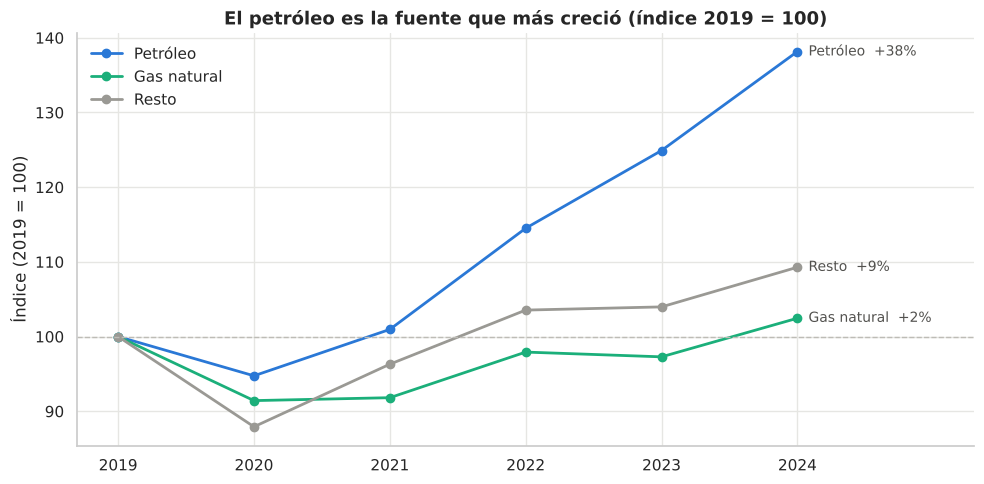

In [5]:
# Índice base 2019 = 100: pone a todas las fuentes en la misma escala
# (el petróleo y el "resto" tienen tamaños muy distintos, así se comparan los ritmos de crecimiento)
indice = prod.div(prod[2019], axis=0) * 100

fig, ax = plt.subplots()
for fuente, color in [("Petróleo", COLOR["petroleo"]), ("Gas natural", COLOR["gas"]), ("Resto", COLOR["resto"])]:
    ax.plot(indice.columns, indice.loc[fuente], marker="o", lw=2, color=color, label=fuente)
    ax.annotate(f"{fuente}  {indice.loc[fuente, 2024]-100:+.0f}%", (2024, indice.loc[fuente, 2024]),
                xytext=(8, 0), textcoords="offset points", va="center", color=COLOR["texto"], fontsize=10)
ax.axhline(100, color="#bdbcb6", lw=1, ls="--")
ax.set_title("El petróleo es la fuente que más creció (índice 2019 = 100)")
ax.set_ylabel("Índice (2019 = 100)")
ax.set_xlim(2018.7, 2025.3)
ax.set_xticks(AÑOS)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "1_produccion_indice.png", dpi=150)
plt.show()

**Lectura:**
- La producción de energía primaria creció un **15,2%** entre 2019 y 2024 (de 78.240 a 90.128 miles de TEP).
- El **petróleo creció un 38%** y explica por sí solo el **84% de ese aumento**. El gas natural apenas creció un 2,5%.
- 2020 marca la caída por la pandemia; desde 2021 el petróleo se despega del resto.
- La base no separa la producción por cuenca, así que no "ve" Vaca Muerta directamente. Pero el salto del petróleo coincide con el
  desarrollo no convencional de esa formación, que según fuentes del sector es el motor del crecimiento de la producción en este período.

### 1.2 Comercio exterior: exportaciones vs. importaciones

Acá **sí sumamos primaria + secundaria**, porque en el comercio no hay doble conteo: cada producto cruza la frontera una sola vez
(el petróleo crudo que se exporta no es el mismo que se refina y se vende como gasoil).

Construimos tres indicadores:
- **Saldo comercial energético** = Exportaciones − Importaciones. Positivo → el país vende más energía de la que compra.
- **Tasa de cobertura** = Exportaciones / Importaciones. Mayor a 1 → las ventas cubren las compras.
- **Saldo sin nuclear**: el balance argentino registra toda la energía nuclear como *importada* (por el combustible de uranio).
  Es una convención contable, así que mostramos también el saldo sin ella para ver que la conclusión no depende de eso.

In [6]:
expo = serie("EXPORTACIÓN Y BUNKER").abs()
impo = serie("IMPORTACIÓN")
impo_nuclear = serie("IMPORTACIÓN", fuentes=["Energía Nuclear"])

comercio = pd.DataFrame({
    "Exportaciones": expo,
    "Importaciones": impo,
    "Saldo": expo - impo,
    "Tasa de cobertura": expo / impo,
    "Saldo sin nuclear": expo - (impo - impo_nuclear),
}).round(2)
comercio

,Exportaciones,Importaciones,Saldo,Tasa de cobertura,Saldo sin nuclear
año,,,,,
2019,9362.69,12205.77,-2843.08,0.77,-642.96
2020,8610.10,12062.27,-3452.17,0.71,-673.70
2021,8074.55,15785.54,-7710.99,0.51,-4888.43
2022,13686.56,15852.44,-2165.88,0.86,-92.85
2023,13056.46,11595.27,1461.19,1.13,3948.83
2024,17499.49,7830.90,9668.59,2.23,12568.67


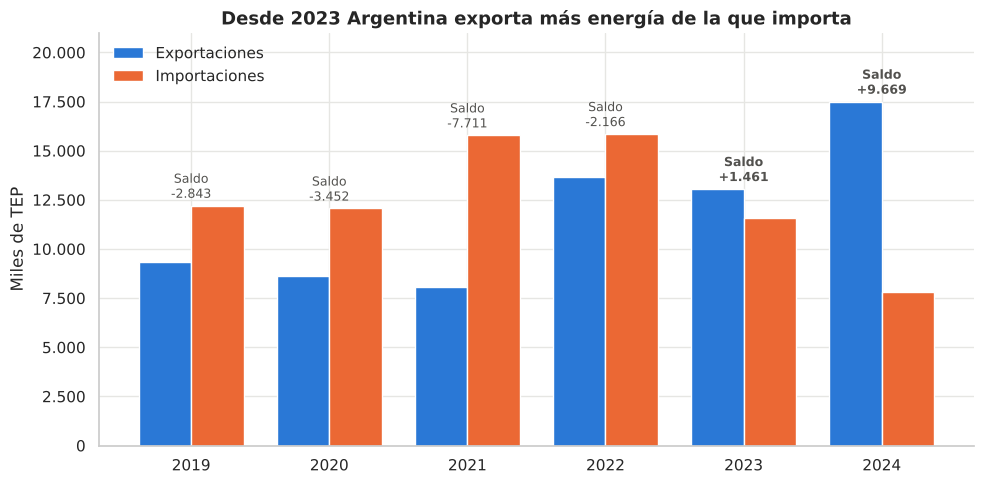

In [7]:
fig, ax = plt.subplots()
x = np.arange(len(AÑOS))
ancho = 0.38
ax.bar(x - ancho/2, comercio["Exportaciones"], ancho, color=COLOR["exportacion"], label="Exportaciones")
ax.bar(x + ancho/2, comercio["Importaciones"], ancho, color=COLOR["importacion"], label="Importaciones")

# Etiqueta del saldo encima de cada par de barras
for i, año in enumerate(AÑOS):
    saldo = comercio.loc[año, "Saldo"]
    alto = max(comercio.loc[año, "Exportaciones"], comercio.loc[año, "Importaciones"])
    ax.text(i, alto + 400, f"Saldo\n{saldo:+,.0f}".replace(",", "."), ha="center", fontsize=9,
            color=COLOR["texto"], fontweight="bold" if saldo > 0 else "normal")

ax.set_xticks(x, AÑOS)
ax.set_ylim(0, comercio[["Exportaciones", "Importaciones"]].max().max() * 1.2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_ylabel("Miles de TEP")
ax.set_title("Desde 2023 Argentina exporta más energía de la que importa")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "2_exportaciones_vs_importaciones.png", dpi=150)
plt.show()

**Lectura:**
- El saldo pasó de **−2.843** miles de TEP en 2019 a **+9.669** en 2024. **El cambio de signo ocurre en 2023.**
- El peor año fue **2021** (−7.711): la economía se reactivó después de la pandemia y las importaciones llegaron a su máximo.
- La **tasa de cobertura** pasó de 0,77 a **2,23**: en 2024 Argentina exportó más del doble de la energía que importó.
- El giro se produce por los dos lados a la vez: las exportaciones crecieron un **87%** y las importaciones cayeron un **36%**.
- Sin la energía nuclear el resultado es el mismo (el saldo también se vuelve positivo en 2023), así que la conclusión no depende de esa convención contable.

### 1.3 ¿Qué productos explican el cambio?

El saldo puede mejorar por dos caminos: **exportar más** o **importar menos**. Para cada producto calculamos cuánto cambió su
saldo propio (exportaciones − importaciones) entre 2019 y 2024. La suma de todas las barras es el cambio total del saldo.

In [8]:
expo_f = serie("EXPORTACIÓN Y BUNKER", por_fuente=True).abs()
impo_f = serie("IMPORTACIÓN", por_fuente=True)
saldo_f = expo_f.reindex(expo_f.index.union(impo_f.index), fill_value=0) \
        - impo_f.reindex(expo_f.index.union(impo_f.index), fill_value=0)

cambio = (saldo_f[2024] - saldo_f[2019]).sort_values()
# Nos quedamos con los productos que movieron más de 100 miles de TEP; el resto va a "Otros"
grandes = cambio[cambio.abs() >= 100]
cambio_graf = pd.concat([grandes, pd.Series({"Otros": cambio[cambio.abs() < 100].sum()})]).sort_values()

print(f"Cambio total del saldo 2019→2024: {cambio.sum():+,.0f} miles de TEP")
cambio_graf.round(0).to_frame("Cambio del saldo 2019→2024")

Cambio total del saldo 2019→2024: +12,512 miles de TEP


,Cambio del saldo 2019→2024
Energía Nuclear,-700.0
Biodiesel,-562.0
Carbón Mineral,-208.0
Otros,92.0
Kerosene y Aerokerosene,113.0
Energía Eléctrica,131.0
Motonafta Total,208.0
Gas Natural de Pozo,218.0
Otras Naftas,401.0
Diesel Oil + Gas Oil,1414.0


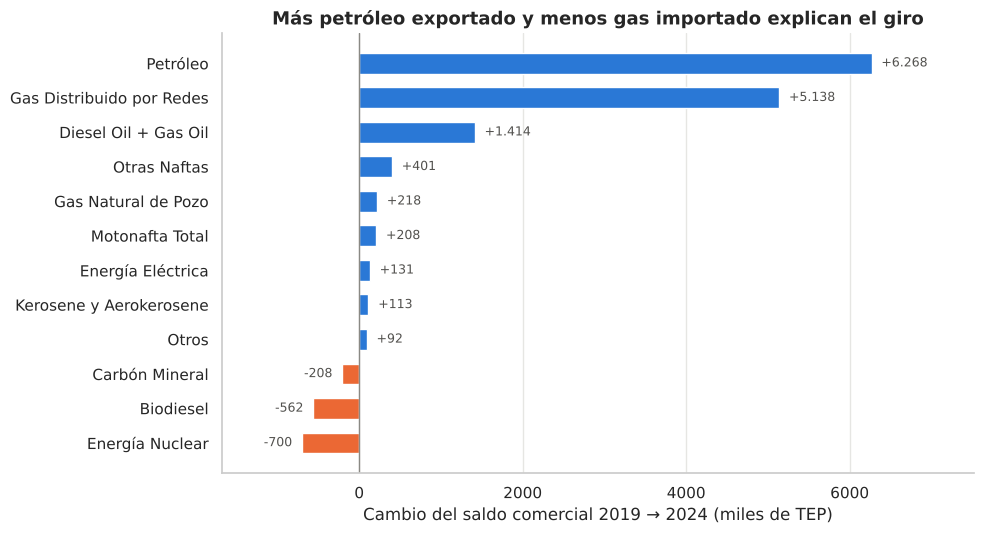

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colores = [COLOR["saldo_pos"] if v > 0 else COLOR["saldo_neg"] for v in cambio_graf]
ax.barh(cambio_graf.index, cambio_graf.values, color=colores, height=0.6)
for i, v in enumerate(cambio_graf.values):
    ax.text(v + (120 if v >= 0 else -120), i, f"{v:+,.0f}".replace(",", "."), va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=COLOR["texto"])
ax.axvline(0, color="#8a8984", lw=1)
ax.set_xlabel("Cambio del saldo comercial 2019 → 2024 (miles de TEP)")
ax.set_title("Más petróleo exportado y menos gas importado explican el giro")
ax.set_xlim(cambio_graf.min() * 2.4, cambio_graf.max() * 1.2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "3_cambio_saldo_por_producto.png", dpi=150)
plt.show()

**Lectura:**
- De la mejora total del saldo (+12.512 miles de TEP), **el petróleo aporta la mitad** (+6.268): son las exportaciones de crudo.
- La otra gran parte es el **gas** (+5.138): Argentina importaba 5.698 miles de TEP de gas en 2019 y 2.293 en 2024, y además empezó a exportarlo.
  Más gas propio significa menos barcos de GNL y menos gas importado de Bolivia.
- El **gasoil** también suma (+1.414) porque se importa menos.
- Lo que resta es menor: el **biodiésel** se exporta menos y la **nuclear** aparece como más "importada" (convención contable).
- Conclusión: **el país no solo vende más energía, también dejó de comprar la que antes le faltaba**, sobre todo gas.

### 1.4 Autoabastecimiento

**Índice de autoabastecimiento = Producción primaria / Oferta interna primaria**

La *oferta interna* es la energía que el país tiene disponible para usar (producción + importaciones − exportaciones ± stock).
- Índice **> 100%** → el país produce más energía de la que necesita: le sobra para exportar.
- Índice **< 100%** → necesita importar para cubrir su demanda.

In [10]:
oferta_interna = serie("OFERTA INTERNA", tipo="PRIMARIA")
produccion_prim = serie("PRODUCCIÓN", tipo="PRIMARIA")
autoabastecimiento = (produccion_prim / oferta_interna * 100).round(1)
autoabastecimiento.to_frame("Autoabastecimiento %")

,Autoabastecimiento %
año,
2019,101.4
2020,102.2
2021,99.5
2022,104.3
2023,105.7
2024,108.7


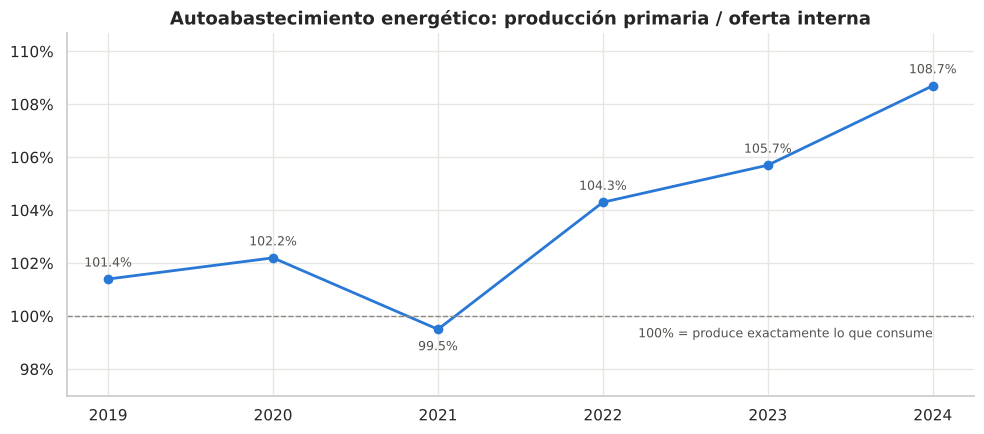

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(AÑOS, autoabastecimiento, marker="o", lw=2, color=COLOR["exportacion"])
ax.axhline(100, color="#8a8984", lw=1, ls="--")
ax.text(2024, 99.2, "100% = produce exactamente lo que consume", fontsize=9, color=COLOR["texto"], ha="right")
for año, v in autoabastecimiento.items():
    abajo = v < 100   # la etiqueta de 2021 va debajo del punto para no pisar la línea del 100%
    ax.annotate(f"{v:.1f}%", (año, v), xytext=(0, -15 if abajo else 9), textcoords="offset points",
                ha="center", fontsize=9, color=COLOR["texto"])
ax.set_ylim(97, autoabastecimiento.max() + 2)
ax.set_xticks(AÑOS)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Autoabastecimiento energético: producción primaria / oferta interna")
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "4_autoabastecimiento.png", dpi=150)
plt.show()

**Lectura:**
- Argentina se autoabastece en casi todo el período, y el índice sube de **101,4%** en 2019 a **108,7%** en 2024.
- El único año por debajo de 100% es **2021** (99,5%), el mismo año en que el saldo comercial tocó su peor valor. Los dos indicadores cuentan la misma historia.
- Desde 2022 el país produce cada vez más energía de la que consume: ese "sobrante" es lo que se exporta.

---
## 2. TRANSFORMACIÓN: ¿cuánta energía se pierde al convertirla?

Gran parte de la energía primaria no se usa tal cual: el petróleo pasa por **refinerías**, el gas de pozo por **plantas de tratamiento**
y muchos combustibles se queman en **centrales eléctricas** para producir electricidad. En cada conversión se pierde algo.

**Eficiencia de transformación = Energía que sale / Energía que entra**

En la base, dentro de cada centro de transformación, los insumos aparecen con signo negativo y los productos con signo positivo,
así que: *sale* = suma de los positivos; *entra* = suma de los negativos en valor absoluto.

> Nota 1: las **plantas de tratamiento de gas** dan siempre 100% porque el balance registra que todo el gas que entra sale
> como gas procesado (más gas licuado y gasolina). No aportan información, así que las dejamos fuera del gráfico.
>
> Nota 2: en las centrales eléctricas, la energía hidráulica, eólica y solar se registra con un criterio contable distinto al de los
> combustibles. Por eso comparamos la eficiencia de cada centro **a lo largo del tiempo**, no entre centros.

In [12]:
CENTROS = {
    "PLANTAS DE TRATAMIENTO DE GAS": "Plantas de gas",
    "REFINERÍAS": "Refinerías",
    "CENTRALES ELÉCTRICAS - SERVICIO PÚBLICO": "Centrales eléctricas",
}
transf = detalle[detalle["categoria"] == "CENTROS DE TRANSFORMACIÓN"]

def eficiencia(d):
    sale = d.loc[d["valor_miles_TEP"] > 0, "valor_miles_TEP"].sum()
    entra = d.loc[d["valor_miles_TEP"] < 0, "valor_miles_TEP"].abs().sum()
    return pd.Series({"Entra": entra, "Sale": sale, "Pérdida": entra - sale, "Eficiencia %": sale / entra * 100})

efic = (transf[transf["subcategoria"].isin(CENTROS)]
        .groupby(["subcategoria", "año"]).apply(eficiencia).round(1))
efic_total = transf.groupby("año").apply(eficiencia).round(1)

tabla_efic = efic["Eficiencia %"].unstack("año").rename(index=CENTROS)
tabla_efic.loc["Todos los centros"] = efic_total["Eficiencia %"]
tabla_efic

año,2019,2020,2021,2022,2023,2024
subcategoria,,,,,,
Centrales eléctricas,56.4,57.1,53.0,53.4,56.9,55.3
Plantas de gas,100.0,100.0,100.0,100.0,100.0,100.0
Refinerías,91.3,94.7,93.4,93.3,93.9,91.7
Todos los centros,85.4,85.7,83.8,84.7,86.0,84.3


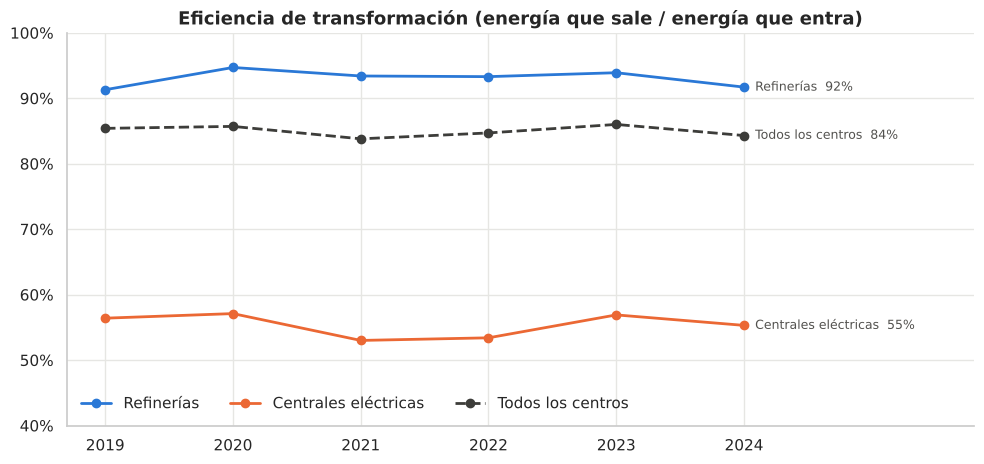

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
estilos = {"Refinerías": COLOR["petroleo"],
           "Centrales eléctricas": COLOR["importacion"], "Todos los centros": "#3d3d3a"}
for centro, color in estilos.items():
    ls = "--" if centro == "Todos los centros" else "-"
    ax.plot(AÑOS, tabla_efic.loc[centro], marker="o", lw=2, ls=ls, color=color, label=centro)
    ax.annotate(f"{centro}  {tabla_efic.loc[centro, 2024]:.0f}%", (2024, tabla_efic.loc[centro, 2024]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=COLOR["texto"])
ax.set_xlim(2018.7, 2025.8)
ax.set_xticks(AÑOS)
ax.set_ylim(40, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Eficiencia de transformación (energía que sale / energía que entra)")
ax.legend(loc="lower left", frameon=False, ncol=3)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "5_eficiencia_transformacion.png", dpi=150)
plt.show()

**Lectura:**
- Las **refinerías** convierten el 91–95% de lo que reciben; las **centrales eléctricas** solo el 53–57%. Es normal en centrales que queman gas:
  buena parte de la energía se va en calor.
- La eficiencia de **todos los centros** se mantiene estable en torno al **84–86%** durante todo el período.
- Esto descarta una explicación alternativa: **el giro exportador no vino de transformar mejor la energía**, sino de **producir más**.

---
## 3. CONSUMO: ¿la energía extra se usa en el país o se va afuera?

Si la producción crece, esa energía tiene dos destinos posibles: **se consume adentro** o **se exporta**.
Comparamos las tres series con el mismo índice (2019 = 100). Para el consumo usamos las filas `TOTAL GENERAL`
(primaria + secundaria) que trae la base, que sí son correctas porque el consumo final no tiene doble conteo.

In [14]:
consumo_gral = df[df["tipo_energia"] == "TOTAL GENERAL"].pivot_table(
    index="subcategoria", columns="año", values="valor_miles_TEP", aggfunc="sum")
consumo_final = consumo_gral.loc["CONSUMO FINAL - TOTAL"]

destinos = pd.DataFrame({
    "Producción primaria": produccion_prim,
    "Consumo final": consumo_final,
    "Exportaciones": expo,
})
destinos_idx = (destinos / destinos.loc[2019] * 100).round(1)
destinos_idx

,Producción primaria,Consumo final,Exportaciones
año,,,
2019,100.0,100.0,100.0
2020,92.2,91.3,92.0
2021,95.4,100.0,86.2
2022,104.1,102.2,146.2
2023,107.3,100.8,139.5
2024,115.2,98.0,186.9


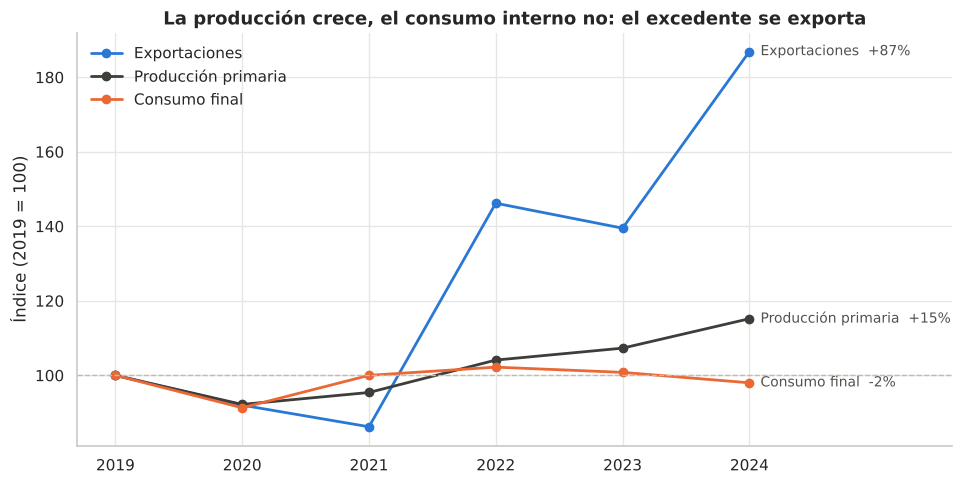

In [15]:
fig, ax = plt.subplots()
for serie_n, color in [("Exportaciones", COLOR["exportacion"]), ("Producción primaria", "#3d3d3a"),
                       ("Consumo final", COLOR["consumo"])]:
    ax.plot(AÑOS, destinos_idx[serie_n], marker="o", lw=2, color=color, label=serie_n)
    ax.annotate(f"{serie_n}  {destinos_idx.loc[2024, serie_n]-100:+.0f}%", (2024, destinos_idx.loc[2024, serie_n]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=10, color=COLOR["texto"])
ax.axhline(100, color="#bdbcb6", lw=1, ls="--")
ax.set_xlim(2018.7, 2025.6)
ax.set_xticks(AÑOS)
ax.set_ylabel("Índice (2019 = 100)")
ax.set_title("La producción crece, el consumo interno no: el excedente se exporta")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "6_produccion_consumo_exportacion.png", dpi=150)
plt.show()

**Lectura:**
- Entre 2019 y 2024 la **producción primaria creció un 15%**, el **consumo final cayó un 2%** y las **exportaciones crecieron un 87%**.
- En números: la producción aumentó en ~11.900 miles de TEP, mientras el consumo final bajó ~1.100. Prácticamente
  **toda la energía extra encontró destino en el exterior**.
- Este gráfico es la respuesta más directa a la pregunta central: el crecimiento productivo no se quedó en el mercado interno.

### 3.1 Consumo final por sector

¿Algún sector absorbió parte del crecimiento? Miramos la variación de cada uno y el año de la pandemia (2020).

In [16]:
sectores = consumo_gral.loc[[s for s in consumo_gral.index
                             if s.startswith("CONSUMO FINAL -") and s != "CONSUMO FINAL - TOTAL"]]
sectores.index = sectores.index.str.replace("CONSUMO FINAL - ", "").str.capitalize()

tabla_sect = pd.DataFrame({
    "2019": sectores[2019],
    "2024": sectores[2024],
    "Var. 2019→2024 %": (sectores[2024] / sectores[2019] - 1) * 100,
    "Caída 2020 %": (sectores[2020] / sectores[2019] - 1) * 100,
    "Peso en 2024 %": sectores[2024] / sectores[2024].sum() * 100,
}).round(1).sort_values("2024", ascending=False)
tabla_sect

,2019,2024,Var. 2019→2024 %,Caída 2020 %,Peso en 2024 %
subcategoria,,,,,
Transporte,17217.6,16757.5,-2.7,-23.4,30.7
Residencial,13652.6,14873.3,8.9,-0.3,27.2
Industria,13513.9,12528.4,-7.3,-2.0,22.9
Comercial y público,4399.9,4412.8,0.3,-6.0,8.1
Agropecuario,3645.2,3597.5,-1.3,-8.0,6.6
No energético,3257.8,2458.7,-24.5,1.1,4.5


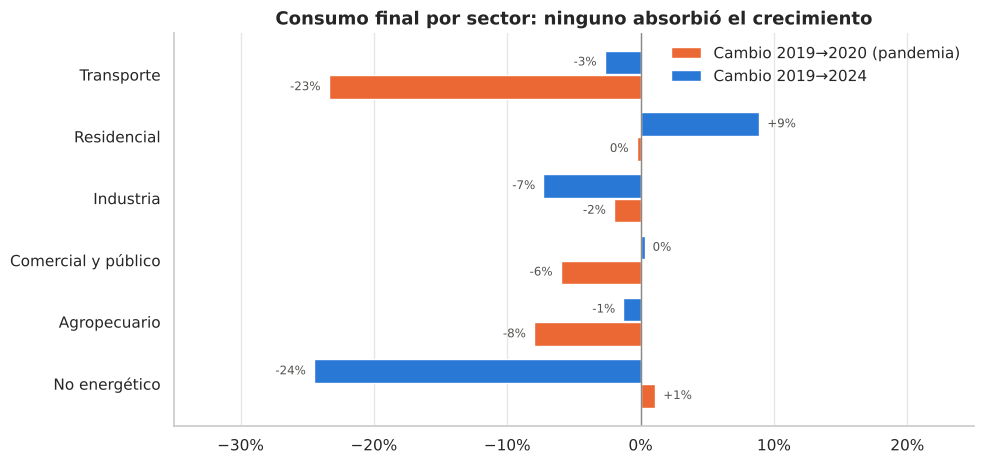

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.8))
orden = tabla_sect.index
y = np.arange(len(orden))
ax.barh(y + 0.2, tabla_sect["Caída 2020 %"], 0.38, color=COLOR["importacion"], label="Cambio 2019→2020 (pandemia)")
ax.barh(y - 0.2, tabla_sect["Var. 2019→2024 %"], 0.38, color=COLOR["exportacion"], label="Cambio 2019→2024")
for i, s in enumerate(orden):
    for dy, col in [(0.2, "Caída 2020 %"), (-0.2, "Var. 2019→2024 %")]:
        v = tabla_sect.loc[s, col]
        ax.text(v + (0.6 if v >= 0 else -0.6), i + dy, f"{v:+.0f}%".replace("-0%", "0%").replace("+0%", "0%"), va="center",
                ha="left" if v >= 0 else "right", fontsize=8.5, color=COLOR["texto"])
ax.set_yticks(y, orden)
ax.invert_yaxis()
ax.axvline(0, color="#8a8984", lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(-35, 25)
ax.grid(axis="y", visible=False)
ax.set_title("Consumo final por sector: ninguno absorbió el crecimiento")
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "7_consumo_por_sector.png", dpi=150)
plt.show()

**Lectura:**
- La pandemia se ve clarísima en el **transporte**: cayó un **23% en 2020**, se recuperó en 2022, y en 2024 sigue un 3% debajo de 2019.
- El **residencial** es el único sector que crece de forma clara (+9%).
- La **industria** consume un 7% menos que en 2019 y el **uso no energético** (insumos petroquímicos) cae casi un 25%, casi todo en 2024.
- Ningún sector absorbió el aumento de la producción, lo que refuerza la conclusión anterior.

---
## 4. Tabla resumen de indicadores

Juntamos todos los indicadores en una sola tabla por año y la exportamos a CSV.
Este archivo se puede abrir directamente en Tableau o Excel para armar un dashboard.

In [18]:
indicadores = pd.DataFrame({
    "produccion_primaria": produccion_prim,
    "produccion_petroleo": prod.loc["Petróleo"],
    "produccion_gas": prod.loc["Gas natural"],
    "oferta_interna_primaria": oferta_interna,
    "exportaciones": expo,
    "importaciones": impo,
    "saldo_comercial": expo - impo,
    "saldo_sin_nuclear": comercio["Saldo sin nuclear"],
    "tasa_cobertura": comercio["Tasa de cobertura"],
    "autoabastecimiento_pct": autoabastecimiento,
    "eficiencia_transformacion_pct": tabla_efic.loc["Todos los centros"],
    "consumo_final": consumo_final,
}).round(2)
indicadores.index.name = "año"

indicadores.to_csv("indicadores_energia_2019_2024.csv", encoding="utf-8-sig")
print("Archivo exportado: indicadores_energia_2019_2024.csv")
indicadores.T

Archivo exportado: indicadores_energia_2019_2024.csv


año,2019,2020,2021,2022,2023,2024
produccion_primaria,78239.97,72102.52,74626.30,81454.42,83949.44,90128.45
produccion_petroleo,26269.33,24889.35,26521.30,30078.54,32812.35,36292.75
produccion_gas,43347.72,39631.43,39800.93,42447.34,42171.58,44412.42
oferta_interna_primaria,77191.20,70557.66,75022.24,78101.31,79401.33,82931.31
exportaciones,9362.69,8610.10,8074.55,13686.56,13056.46,17499.49
importaciones,12205.77,12062.27,15785.54,15852.44,11595.27,7830.90
saldo_comercial,-2843.08,-3452.17,-7710.99,-2165.88,1461.19,9668.59
saldo_sin_nuclear,-642.96,-673.70,-4888.43,-92.85,3948.83,12568.67
tasa_cobertura,0.77,0.71,0.51,0.86,1.13,2.23
autoabastecimiento_pct,101.40,102.20,99.50,104.30,105.70,108.70


## 5. Conclusiones

### Respuesta a la pregunta central

**Sí: entre 2019 y 2024 Argentina pasó de importar energía a exportarla.** El cambio de signo del saldo comercial energético ocurre en **2023**,
y en 2024 el país ya exporta **2,2 veces** la energía que importa.

### ¿Qué lo explica? La historia en tres etapas

1. **Oferta:** la producción primaria creció un 15%, y el **petróleo** explica el 84% de ese aumento (+38%). El crecimiento coincide con el
   desarrollo de **Vaca Muerta**. Al mismo tiempo, la mayor disponibilidad de gas propio redujo fuertemente las importaciones de gas.
2. **Transformación:** la eficiencia de refinerías y centrales se mantuvo estable (~84–86% en total). El giro **no** vino de transformar mejor la energía.
3. **Consumo:** el consumo final interno cayó un 2%. Como el país consume lo mismo pero produce más, **el excedente se exporta**.

| Indicador | 2019 | 2024 |
|---|---|---|
| Producción primaria (miles de TEP) | 78.240 | 90.128 |
| Saldo comercial energético (miles de TEP) | −2.843 | +9.669 |
| Tasa de cobertura (expo / impo) | 0,77 | 2,23 |
| Autoabastecimiento | 101,4% | 108,7% |
| Eficiencia de transformación | 85,4% | 84,3% |
| Consumo final (miles de TEP) | 55.685 | 54.580 |

### Limitaciones del análisis

- **Unidades físicas, no dólares.** Medimos energía (TEP), no plata. El saldo en dólares depende además de los precios internacionales.
  Las fuentes del sector coinciden en la misma dirección: 2024 fue el primer año con superávit comercial energético en dólares en más de una década.
- **La base no separa por cuenca**, así que atribuir el crecimiento a Vaca Muerta usa contexto externo, no la base en sí.
- **"Exportación y bunker"** incluye el combustible que se vende a barcos y aviones internacionales, no solo exportaciones en sentido estricto.
- **Energía nuclear:** se registra como importada por convención. Por eso mostramos el saldo con y sin ella.
- **Solo 6 años de datos**: alcanzan para describir la tendencia, pero no para proyectarla con confianza.

### Próximos pasos posibles

- Sumar datos de **precios / comercio en dólares** (INDEC) para medir el impacto económico del giro.
- Cruzar con **producción por cuenca** (Secretaría de Energía) para medir directamente el peso de Vaca Muerta.
- Armar un **dashboard en Tableau** con `indicadores_energia_2019_2024.csv`.

**Fuentes de contexto:**
- Secretaría de Energía – Balance Energético Nacional (datos de la base).
- [DEF Online – Cómo llegó Argentina al superávit comercial energético después de 14 años](https://defonline.com.ar/energia-mineria/como-llego-argentina-al-superavit-comercial-energetico-despues-de-14-anos/)
- [Más Energía (LM Neuquén) – El aporte de Vaca Muerta al superávit comercial récord de 2024](https://mase.lmneuquen.com/economia/el-aporte-vaca-muerta-el-superavit-comercial-record-del-2024-n1169219)